In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import cv2
import os

%matplotlib inline

In [2]:
# Paths - update for your image
IMAGE_NAME = 'bed_back_bedroom'
BASE_PATH = Path(f'../rgb-x_output/batch_output/')

normal_path = BASE_PATH / f"{IMAGE_NAME}_normal.npy"
rgb_path = BASE_PATH / f"{IMAGE_NAME}.jpg"
normal_path = BASE_PATH / IMAGE_NAME / f"{IMAGE_NAME}_normal_preview.png"
img_path = BASE_PATH / IMAGE_NAME / f"{IMAGE_NAME}.jpg"
wall_conf_path = BASE_PATH / IMAGE_NAME / f"{IMAGE_NAME}_wall_confidence.npy"
if(os.path.exists(img_path)):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert to RGB for display
    print("RGB Image Shape: ", img.shape)

nor_img = cv2.cvtColor(cv2.imread(str(normal_path)), cv2.COLOR_BGR2RGB)
print("Shape: ", nor_img.shape)

# Reshape to (num_pixels, 3) to treat each pixel as an RGB triplet
pixels = nor_img.reshape(-1, 3)
total_pixels = pixels.shape[0]

# Find unique RGB combinations
unique_colors = np.unique(pixels, axis=0)
num_unique = len(unique_colors)

# Calculate percentage of unique pixels
percentage_unique = (num_unique / total_pixels) * 100

print(f"{IMAGE_NAME} - Shape: {nor_img.shape}")
print(f"Total pixels: {total_pixels}")
print(f"Unique RGB combinations: {num_unique}")
print(f"Percentage of unique colors: {percentage_unique:.2f}%")

RGB Image Shape:  (700, 1200, 3)
Shape:  (700, 1200, 3)
bed_back_bedroom - Shape: (700, 1200, 3)
Total pixels: 840000
Unique RGB combinations: 252667
Percentage of unique colors: 30.08%


## Clustering Normal Map using KMeans

In [3]:
import numpy as np
from sklearn.cluster import KMeans
import cv2
from PIL import Image

# Load image
img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)

# Reshape to 2D array of pixels
pixels = nor_img.reshape(-1, 3)

# Apply KMeans (e.g., 5 color clusters)
kmeans = KMeans(n_clusters=20, random_state=42)
labels = kmeans.fit_predict(pixels)

# Replace each pixel with its cluster center
clustered_img = kmeans.cluster_centers_[labels]
clustered_img = clustered_img.reshape(img.shape).astype(np.uint8)

kmeans.cluster_centers_

/Users/ishan-aiworkspace/Documents/apps/rgb-x/Notebook for Output visualisation/venv_notebook/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/ishan-aiworkspace/Documents/apps/rgb-x/Notebook for Output visualisation/venv_notebook/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/ishan-aiworkspace/Documents/apps/rgb-x/Notebook for Output visualisation/venv_notebook/lib/python3.13/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/ishan-aiworkspace/Documents/apps/rgb-x/Notebook for Output visualisation/venv_notebook/lib/python3.13/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/ishan-aiworkspace/Documents/apps/rgb-x/Notebook for Output visualisation/venv_notebo

array([[206.6904374 , 137.99696253, 219.04130013],
       [ 35.83269909, 136.57191035, 207.49383688],
       [129.17371722, 247.47861188, 116.8130074 ],
       [128.02455096,   3.42175931, 148.63389662],
       [139.85784683, 138.43387   , 239.57530846],
       [ 51.7820442 , 203.1996547 , 173.94716851],
       [210.9824769 , 160.81118999, 196.98022312],
       [177.04787802, 213.12741575, 177.3136836 ],
       [ 45.2762714 , 100.63238785, 192.59465201],
       [118.68610806, 193.71696794, 215.75931289],
       [107.34393675, 138.53719497, 242.37266559],
       [101.24099353, 238.1219337 , 137.98573335],
       [196.80681934,  97.80732824, 213.08549618],
       [ 29.8248908 , 159.59852609, 185.96073033],
       [166.08917291,  53.64727486, 184.56897312],
       [171.05134393, 150.13514188, 225.48185903],
       [ 69.78001419, 181.98013832, 210.01932967],
       [ 75.54414702,  55.0689173 , 188.62405114],
       [ 70.28805602, 138.18322743, 231.81742016],
       [234.51861882, 137.38629

## Quick check if we can filter by wall confidence metric right after the KMeans

In [4]:
def analyze_cluster_confidence(labels, confidence_mask, n_clusters, threshold=0.5):
    """
    Analyze what percentage of pixels in each cluster cross a confidence threshold.
    
    Parameters:
    -----------
    labels : np.ndarray
        Flattened array of cluster labels for each pixel (from KMeans)
    confidence_mask : np.ndarray
        2D array of confidence scores (same shape as original image, or flattened)
    n_clusters : int
        Number of clusters
    threshold : float
        Confidence threshold (default: 0.5)
    
    Returns:
    --------
    dict : Dictionary with cluster ID as key and dict of stats as value
        {
            cluster_id: {
                'total_pixels': int,
                'pixels_above_threshold': int,
                'percentage_above_threshold': float
            }
        }
    """
    # Flatten confidence mask if needed
    if confidence_mask.ndim > 1:
        confidence_flat = confidence_mask.flatten()
    else:
        confidence_flat = confidence_mask
    
    results = {}
    
    for cluster_id in range(n_clusters):
        # Get mask for current cluster
        cluster_mask = (labels == cluster_id)
        
        # Get confidence values for this cluster
        cluster_confidences = confidence_flat[cluster_mask]
        
        # Calculate statistics
        total_pixels = len(cluster_confidences)
        pixels_above = np.sum(cluster_confidences >= threshold)
        percentage = (pixels_above / total_pixels * 100) if total_pixels > 0 else 0
        
        results[cluster_id] = {
            'total_pixels': total_pixels,
            'pixels_above_threshold': pixels_above,
            'percentage_above_threshold': percentage
        }
    
    return results

In [5]:
# Usage example:
confidence_mask = np.load(wall_conf_path)  # Load confidence mask
results = analyze_cluster_confidence(labels, confidence_mask, n_clusters=20, threshold=0.9)
for cluster_id, stats in results.items():
    print(f"Cluster {cluster_id}: {stats['percentage_above_threshold']:.2f}% above threshold")

Cluster 0: 11.77% above threshold
Cluster 1: 72.29% above threshold
Cluster 2: 0.00% above threshold
Cluster 3: 0.39% above threshold
Cluster 4: 0.02% above threshold
Cluster 5: 0.00% above threshold
Cluster 6: 1.19% above threshold
Cluster 7: 0.00% above threshold
Cluster 8: 1.96% above threshold
Cluster 9: 0.00% above threshold
Cluster 10: 0.01% above threshold
Cluster 11: 0.00% above threshold
Cluster 12: 4.88% above threshold
Cluster 13: 0.00% above threshold
Cluster 14: 3.89% above threshold
Cluster 15: 0.18% above threshold
Cluster 16: 0.00% above threshold
Cluster 17: 0.64% above threshold
Cluster 18: 0.15% above threshold
Cluster 19: 0.00% above threshold


We cannot. Some walls go in clusters that have a lot more pixels from other objects in the scene that are not walls. As a result, the wall confidence can be as low as 45% on an average for a cluster even if it contains the largest wall in the image. 

## VIsualising each cluster's pixels

### Visualisation Helper functions

In [6]:
def overlay_cluster_on_image(original_img, labels, cluster_index, overlay_color=[255, 0, 0], alpha=0.5):
    """
    Overlay a specific cluster on the original image for visualization.
    
    Parameters:
    -----------
    original_img : np.ndarray
        Original image (H, W, 3)
    labels : np.ndarray
        Flattened array of cluster labels for each pixel (from KMeans)
    cluster_index : int
        The cluster ID to visualize
    overlay_color : list or np.ndarray
        RGB color for the overlay (default: red [255, 0, 0])
    alpha : float
        Transparency of overlay (0.0 = transparent, 1.0 = opaque, default: 0.5)
    
    Returns:
    --------
    np.ndarray : Image with cluster overlay
    """
    # Create a copy of the original image
    overlay_img = original_img.copy().astype(np.float32)
    
    # Reshape labels back to image dimensions
    h, w = original_img.shape[:2]
    labels_2d = labels.reshape(h, w)
    
    # Create mask for the selected cluster
    cluster_mask = (labels_2d == cluster_index)
    
    # Create overlay
    overlay_layer = np.zeros_like(overlay_img)
    overlay_layer[cluster_mask] = overlay_color
    
    # Blend original image with overlay
    result = cv2.addWeighted(overlay_img, 1 - alpha, overlay_layer, alpha, 0)
    
    return result.astype(np.uint8)

In [7]:
def visualize_all_clusters(original_img, labels, n_clusters, overlay_color=[255, 0, 0], alpha=0.5):
    """
    Create a 3 images per row pyplot figure showing pixels of each cluster.
    
    Parameters:
    -----------
    original_img : np.ndarray
        Original image (H, W, 3)
    labels : np.ndarray
        Flattened array of cluster labels for each pixel (from KMeans)
    n_clusters : int
        Total number of clusters
    overlay_color : list or np.ndarray
        RGB color for the overlay (default: red [255, 0, 0])
    alpha : float
        Transparency of overlay (0.0 = transparent, 1.0 = opaque, default: 0.5)
    """
    # Calculate rows needed for 3 columns
    n_cols = 3
    n_rows = (n_clusters + n_cols - 1) // n_cols
    
    # Create figure with larger size
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
    
    # Flatten axes array for easier iteration
    if n_clusters > 1:
        axes = axes.flatten()
    else:
        axes = [axes]
    
    # Plot each cluster
    for i in range(n_clusters):
        cluster_overlay = overlay_cluster_on_image(
            original_img, labels, i, overlay_color, alpha
        )
        axes[i].imshow(cluster_overlay)
        axes[i].set_title(f'Cluster {i}', fontsize=14)
        axes[i].axis('off')
    
    # Hide any unused subplots
    for i in range(n_clusters, len(axes)):
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.show()

### Visualised Clusters

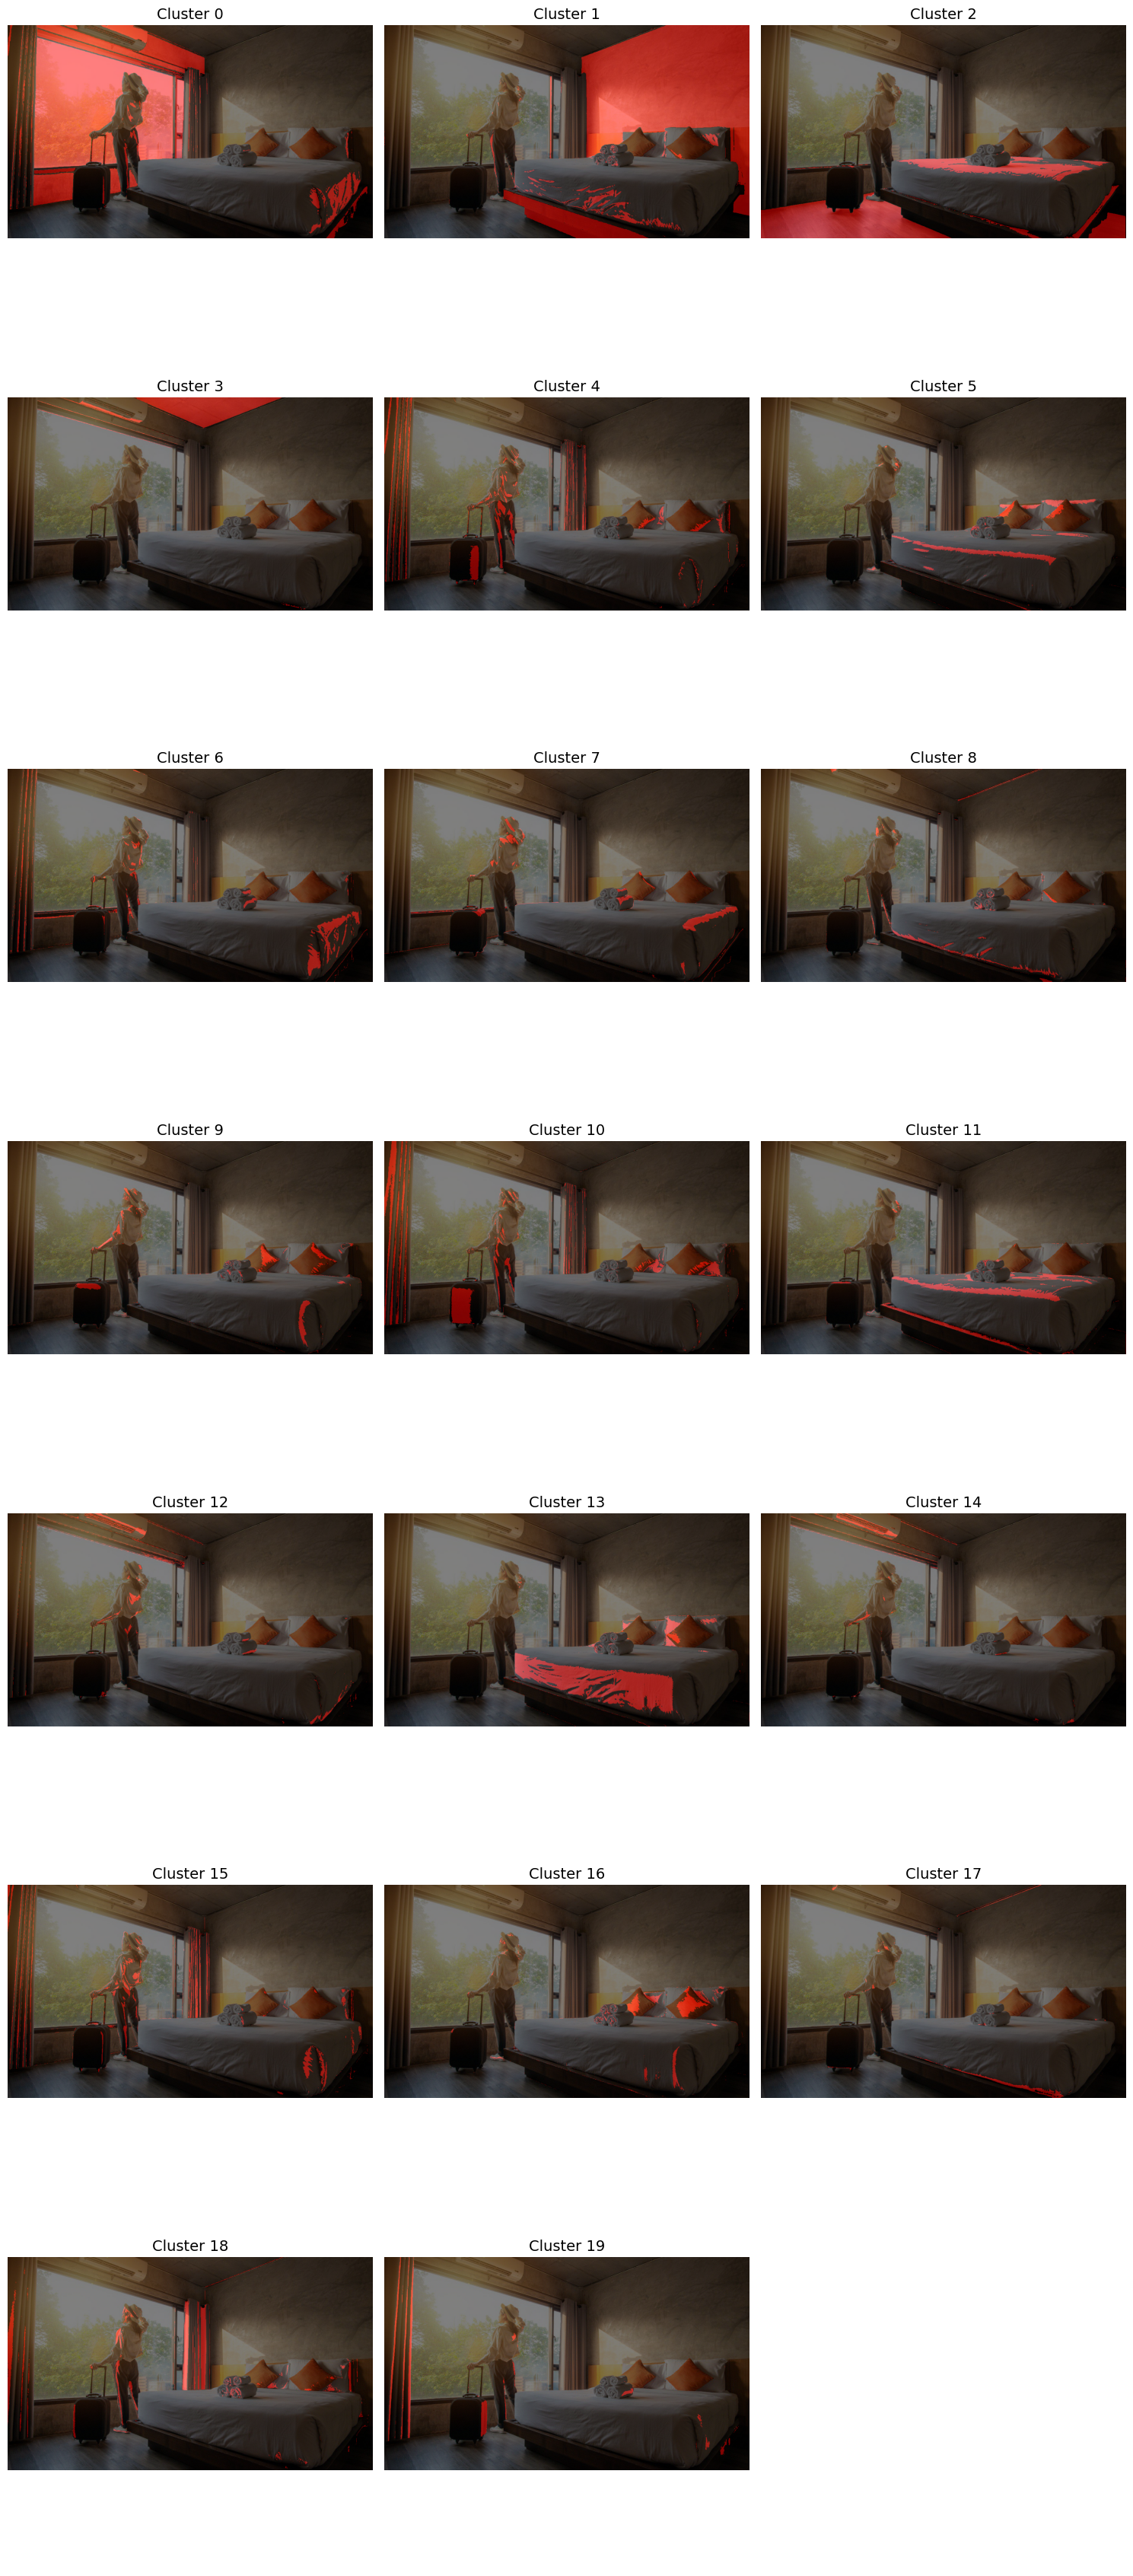

In [8]:
# Assuming you have: original_img, labels from KMeans, and n_clusters
visualize_all_clusters(img, labels, n_clusters=20, alpha=0.5)

## Connected Components in each Cluster

Find connected groups of pixels in each Cluster so that we can separate walls from other items like window frames

### Helper Functions

In [9]:
def find_cluster_subcomponents(labels, img_shape):
    """
    Find connected components within each cluster.
    
    Parameters:
    -----------
    labels : np.ndarray
        Flattened array of cluster labels from KMeans
    img_shape : tuple
        Shape of original image (H, W) or (H, W, C)
    
    Returns:
    --------
    dict : Dictionary mapping cluster_id to its connected components info
        {
            cluster_id: {
                'num_components': int,
                'component_labels': np.ndarray (2D),
                'stats': np.ndarray,
                'centroids': np.ndarray
            }
        }
    """
    # Reshape labels to 2D
    h, w = img_shape[:2]
    labels_2d = labels.reshape(h, w)
    
    results = {}
    n_clusters = len(np.unique(labels))
    
    for cluster_id in range(n_clusters):
        # Create binary mask for this cluster
        cluster_mask = (labels_2d == cluster_id).astype(np.uint8)
        
        # Find connected components within this cluster
        num_labels, component_labels, stats, centroids = cv2.connectedComponentsWithStats(
            cluster_mask, connectivity=8
        )
        
        results[cluster_id] = {
            'num_components': num_labels - 1,  # Subtract 1 to exclude background
            'component_labels': component_labels,
            'stats': stats,  # [x, y, width, height, area] for each component
            'centroids': centroids
        }
    
    return results

In [10]:
def find_cluster_subcomponents_with_threshold(labels, img_shape, min_area_threshold_percent=1.0):
    """
    Find connected components within each cluster and filter by size threshold.
    
    Parameters:
    -----------
    labels : np.ndarray
        Flattened array of cluster labels from KMeans
    img_shape : tuple
        Shape of original image (H, W) or (H, W, C)
    min_area_threshold_percent : float
        Minimum area threshold as percentage of cluster's total area (default: 1.0%)
    
    Returns:
    --------
    dict : Dictionary mapping cluster_id to its connected components info
        {
            cluster_id: {
                'total_cluster_area': int,
                'num_significant_components': int,
                'top_5_components': list of dicts with area stats,
                'all_component_labels': np.ndarray (2D),
                'all_stats': np.ndarray,
                'all_centroids': np.ndarray
            }
        }
    """
    # Reshape labels to 2D
    h, w = img_shape[:2]
    labels_2d = labels.reshape(h, w)
    
    results = {}
    n_clusters = len(np.unique(labels))
    
    for cluster_id in range(n_clusters):
        # Create binary mask for this cluster
        cluster_mask = (labels_2d == cluster_id).astype(np.uint8)
        total_cluster_area = np.sum(cluster_mask)
        
        # Calculate minimum area threshold
        min_area = (min_area_threshold_percent / 100.0) * total_cluster_area
        
        # Find connected components within this cluster
        num_labels, component_labels, stats, centroids = cv2.connectedComponentsWithStats(
            cluster_mask, connectivity=8
        )
        
        # Filter significant components (skip index 0 which is background)
        significant_components = []
        for i in range(1, num_labels):  # Start from 1 to skip background
            area = stats[i, cv2.CC_STAT_AREA]
            if area >= min_area:
                significant_components.append({
                    'component_id': i,
                    'area': area,
                    'x': stats[i, cv2.CC_STAT_LEFT],
                    'y': stats[i, cv2.CC_STAT_TOP],
                    'width': stats[i, cv2.CC_STAT_WIDTH],
                    'height': stats[i, cv2.CC_STAT_HEIGHT],
                    'centroid_x': centroids[i, 0],
                    'centroid_y': centroids[i, 1],
                    'area_percent': (area / total_cluster_area * 100) if total_cluster_area > 0 else 0
                })
        
        # Sort by area (descending) and get top 5
        significant_components.sort(key=lambda x: x['area'], reverse=True)
        top_5 = significant_components[:5]
        
        results[cluster_id] = {
            'total_cluster_area': total_cluster_area,
            'significant_components': significant_components,
            'num_significant_components': len(significant_components),
            'top_5_components': top_5,
            'all_component_labels': component_labels,
            'all_stats': stats,
            'all_centroids': centroids
        }
    
    return results


### Finding Sub Components

In [11]:
# Usage:
subcomponents = find_cluster_subcomponents(labels, img.shape)
for cluster_id, info in subcomponents.items():
    if cluster_id < 5: 
        print(f"Cluster {cluster_id} has {info['num_components']} connected component(s).")

Cluster 0 has 514 connected component(s).
Cluster 1 has 329 connected component(s).
Cluster 2 has 106 connected component(s).
Cluster 3 has 219 connected component(s).
Cluster 4 has 639 connected component(s).


In [12]:

# Usage:
subcomponents = find_cluster_subcomponents_with_threshold(labels, img.shape, min_area_threshold_percent=5.0)
for cluster_id, info in subcomponents.items():
    if cluster_id < 5: 
        total_area_of_top_5 = sum(comp['area'] for comp in info['top_5_components'])
        print(f"\nCluster {cluster_id}:")
        print(f"  Total area: {info['total_cluster_area']} pixels")
        print(f"  % area covered by top 5 components: {100*total_area_of_top_5/info['total_cluster_area']:.2f}%")
        print(f"  Significant components (>= threshold): {info['num_significant_components']}")
        print(f"  Top 5 components:")
        for i, comp in enumerate(info['top_5_components'], 1):
            print(f"    {i}. Area: {comp['area']} pixels ({comp['area_percent']:.2f}%), "
                f"Position: ({comp['x']}, {comp['y']}), Size: {comp['width']}x{comp['height']}")


Cluster 0:
  Total area: 212457 pixels
  % area covered by top 5 components: 83.09%
  Significant components (>= threshold): 4
  Top 5 components:
    1. Area: 129375 pixels (60.89%), Position: (87, 40), Size: 457x430
    2. Area: 18492 pixels (8.70%), Position: (96, 0), Size: 486x164
    3. Area: 16526 pixels (7.78%), Position: (306, 0), Size: 341x169
    4. Area: 12141 pixels (5.71%), Position: (84, 484), Size: 133x109

Cluster 1:
  Total area: 228621 pixels
  % area covered by top 5 components: 94.40%
  Significant components (>= threshold): 2
  Top 5 components:
    1. Area: 191322 pixels (83.69%), Position: (648, 0), Size: 552x627
    2. Area: 24500 pixels (10.72%), Position: (390, 539), Size: 478x161

Cluster 2:
  Total area: 88795 pixels
  % area covered by top 5 components: 92.86%
  Significant components (>= threshold): 3
  Top 5 components:
    1. Area: 56158 pixels (63.24%), Position: (0, 549), Size: 626x151
    2. Area: 18973 pixels (21.37%), Position: (445, 432), Size: 64

## Filtering Subcomponents based on Wall-Confidence Score

### Helper Functions for Wall-Confidence Score based Filtering

In [13]:
subcomponents

{0: {'total_cluster_area': np.uint64(212457),
  'significant_components': [{'component_id': 98,
    'area': np.int32(129375),
    'x': np.int32(87),
    'y': np.int32(40),
    'width': np.int32(457),
    'height': np.int32(430),
    'centroid_x': np.float64(280.2673391304348),
    'centroid_y': np.float64(267.7424463768116),
    'area_percent': np.float64(60.89467515779664)},
   {'component_id': 3,
    'area': np.int32(18492),
    'x': np.int32(96),
    'y': np.int32(0),
    'width': np.int32(486),
    'height': np.int32(164),
    'centroid_x': np.float64(306.0734912394549),
    'centroid_y': np.float64(71.71430889033095),
    'area_percent': np.float64(8.703878902554399)},
   {'component_id': 7,
    'area': np.int32(16526),
    'x': np.int32(306),
    'y': np.int32(0),
    'width': np.int32(341),
    'height': np.int32(169),
    'centroid_x': np.float64(506.3168945903425),
    'centroid_y': np.float64(76.68691758441244),
    'area_percent': np.float64(7.778515181895631)},
   {'compone

In [14]:
def extract_wall_components(
    subcomponents,
    wall_confidence,
    wall_confidence_threshold=0.9
):
    """
    Extract wall components from cluster subcomponents based on wall confidence.
    
    Parameters:
    -----------
    subcomponents : dict
        Dictionary from find_cluster_subcomponents_with_threshold() containing
        cluster_id -> {'significant_components', 'all_component_labels', ...}
    wall_confidence : np.ndarray
        2D array of wall confidence scores (from SegFormer .npy file)
    wall_confidence_threshold : float, optional
        Minimum average confidence to classify as wall (default: 0.9)
    
    Returns:
    --------
    list of dict
        Flat list of wall components, each containing:
        - wall_id: Sequential identifier
        - cluster_id: Source cluster
        - component_id: Component ID within cluster
        - area, x, y, width, height: Component geometry
        - centroid_x, centroid_y: Component centroid
        - area_percent: Percentage of cluster area
        - avg_wall_confidence: Average wall confidence score
        - pixel_mask: Binary mask of component pixels
    """
    wall_components = []
    wall_id = 0
    
    # Iterate over all clusters
    for cluster_id, cluster_info in subcomponents.items():
        component_labels = cluster_info['all_component_labels']
        significant_components = cluster_info['significant_components']
        
        # Iterate over all significant components in this cluster
        for component in significant_components:
            component_id = component['component_id']
            
            # Create binary mask for this component
            pixel_mask = (component_labels == component_id)
            
            # Calculate average wall confidence for pixels in this component
            component_wall_confidences = wall_confidence[pixel_mask]
            avg_confidence = component_wall_confidences.mean()
            
            # Check if component qualifies as a wall
            if avg_confidence >= wall_confidence_threshold:
                # Create wall component dictionary
                wall_component = {
                    'wall_id': wall_id,
                    'cluster_id': cluster_id,
                    'component_id': component_id,
                    'area': component['area'],
                    'x': component['x'],
                    'y': component['y'],
                    'width': component['width'],
                    'height': component['height'],
                    'centroid_x': component['centroid_x'],
                    'centroid_y': component['centroid_y'],
                    'area_percent': component['area_percent'],
                    'avg_wall_confidence': float(avg_confidence),
                    'pixel_mask': pixel_mask,
                    'normal_vector': kmeans.cluster_centers_[cluster_id]
                }
                
                wall_components.append(wall_component)
                wall_id += 1
    
    return wall_components

In [15]:
def overlay_wall_component_on_image(original_img, wall_component, overlay_color=[255, 0, 0], alpha=0.5):
    """
    Overlay a specific wall component on the original image for visualization.
    
    Parameters:
    -----------
    original_img : np.ndarray
        Original image (H, W, 3)
    wall_component : dict
        Wall component dictionary containing 'pixel_mask' key
    overlay_color : list or np.ndarray
        RGB color for the overlay (default: red [255, 0, 0])
    alpha : float
        Transparency of overlay (0.0 = transparent, 1.0 = opaque, default: 0.5)
    
    Returns:
    --------
    np.ndarray : Image with wall component overlay
    """
    # Create a copy of the original image
    overlay_img = original_img.copy().astype(np.float32)
    
    # Get the pixel mask from wall component
    pixel_mask = wall_component['pixel_mask']
    
    # Create overlay
    overlay_layer = np.zeros_like(overlay_img)
    overlay_layer[pixel_mask] = overlay_color
    
    # Blend original image with overlay
    result = cv2.addWeighted(overlay_img, 1 - alpha, overlay_layer, alpha, 0)
    
    return result.astype(np.uint8)


### Finding Wall Components

In [16]:
# Load wall confidence from SegFormer output
wall_confidence = np.load(wall_conf_path)

# Extract wall components
wall_components = extract_wall_components(
    subcomponents, 
    wall_confidence, 
    wall_confidence_threshold=0.5
)

# Iterate over wall components
for wall in wall_components:
    print(f"Wall {wall['wall_id']} from cluster {wall['cluster_id']}:")
    print(f"  Area: {wall['area']} pixels")
    print(f"  Position: ({wall['x']}, {wall['y']})")
    print(f"  Size: {wall['width']}x{wall['height']}")
    print(f"  Wall confidence: {wall['avg_wall_confidence']:.3f}")
    print(f"Wall Normal: {wall['normal_vector']}")
    
    # Access the pixel mask
    mask = wall['pixel_mask']
    # Use mask for visualization, analysis, etc.

Wall 0 from cluster 0:
  Area: 18492 pixels
  Position: (96, 0)
  Size: 486x164
  Wall confidence: 0.633
Wall Normal: [206.6904374  137.99696253 219.04130013]
Wall 1 from cluster 0:
  Area: 16526 pixels
  Position: (306, 0)
  Size: 341x169
  Wall confidence: 0.927
Wall Normal: [206.6904374  137.99696253 219.04130013]
Wall 2 from cluster 0:
  Area: 12141 pixels
  Position: (84, 484)
  Size: 133x109
  Wall confidence: 0.935
Wall Normal: [206.6904374  137.99696253 219.04130013]
Wall 3 from cluster 1:
  Area: 191322 pixels
  Position: (648, 0)
  Size: 552x627
  Wall confidence: 0.924
Wall Normal: [ 35.83269909 136.57191035 207.49383688]
Wall 4 from cluster 3:
  Area: 1793 pixels
  Position: (197, 7)
  Size: 246x76
  Wall confidence: 0.811
Wall Normal: [128.02455096   3.42175931 148.63389662]
Wall 5 from cluster 8:
  Area: 698 pixels
  Position: (647, 12)
  Size: 238x94
  Wall confidence: 0.720
Wall Normal: [ 45.2762714  100.63238785 192.59465201]
Wall 6 from cluster 12:
  Area: 1387 pixels

Normal Vector calculation is: 
Load normal preview image using cv2.imread and then use cv2.cvtColor and convert from BGR2RBG
Next use X - 128 and normalise to get the unit vectors so that the z vector is leaving out of the plane of the image towards the camera, x vector is oriented to the right and y vector upward.

[206.6904374  137.99696253 219.04130013] [0.65167885 0.08279035 0.75396315]


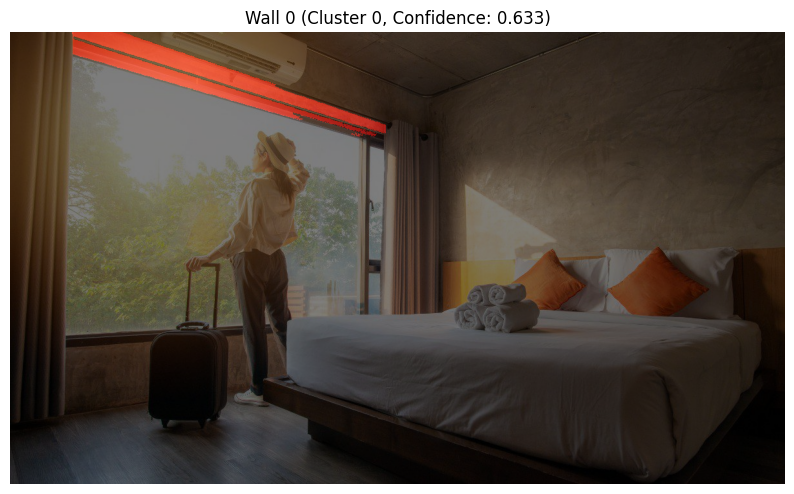

[206.6904374  137.99696253 219.04130013] [0.65167885 0.08279035 0.75396315]


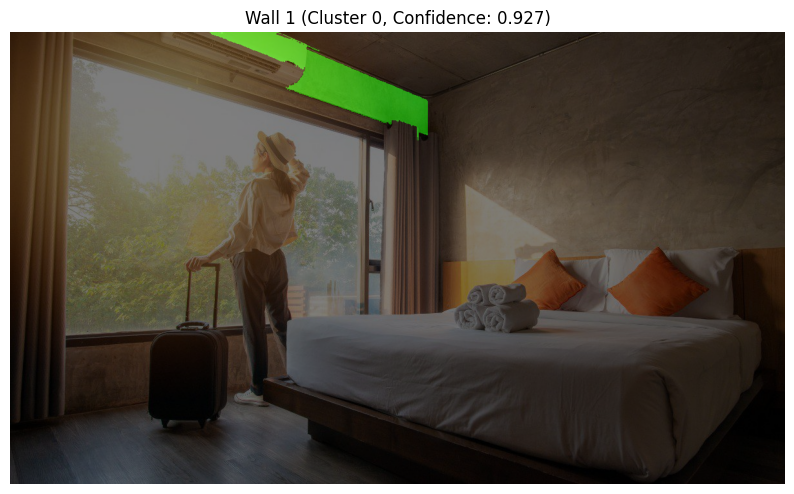

[206.6904374  137.99696253 219.04130013] [0.65167885 0.08279035 0.75396315]


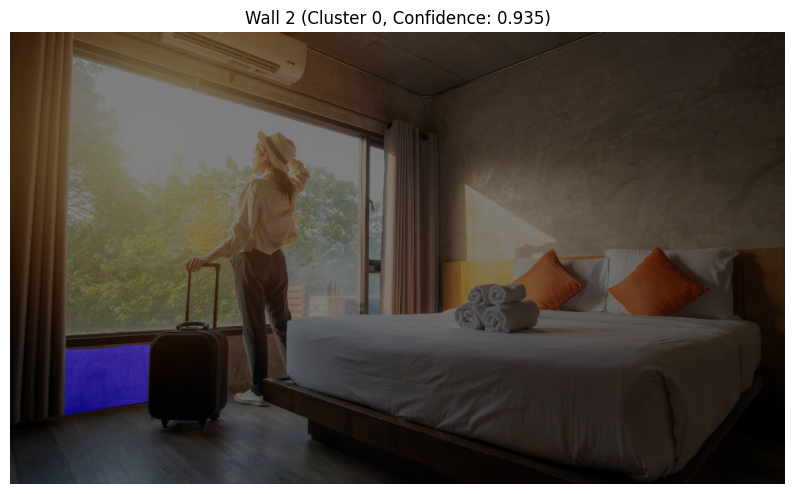

[ 35.83269909 136.57191035 207.49383688] [-0.75537937  0.07025316  0.65151094]


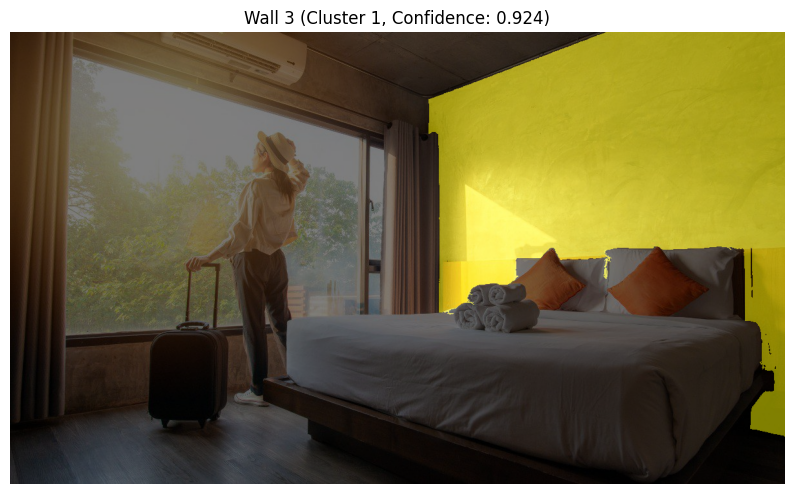

[128.02455096   3.42175931 148.63389662] [ 1.94423828e-04 -9.86559249e-01  1.63403829e-01]


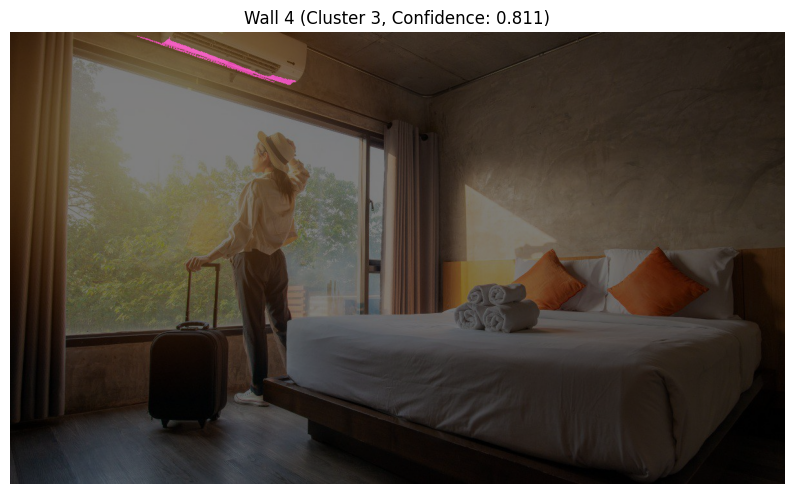

In [17]:
# Or visualize all walls with different colors
colors = [[255, 0, 0], [0, 255, 0], [0, 0, 255], [255, 255, 0], [255, 0, 255]]
for i, wall in enumerate(wall_components[:5]):
    wall_overlay = overlay_wall_component_on_image(
        img, 
        wall, 
        overlay_color=colors[i % len(colors)],
        alpha=0.5
    )
    normal_vector_rgb = wall['normal_vector'] # Replace with your actual wall normal
    normal_vector = normal_vector_rgb - 128 
    normal_unit = normal_vector / np.linalg.norm(normal_vector)
    print(normal_vector_rgb, normal_unit)
    plt.figure(figsize=(10, 8))
    plt.imshow(wall_overlay)
    plt.title(f"Wall {wall['wall_id']} (Cluster {wall['cluster_id']}, Confidence: {wall['avg_wall_confidence']:.3f})")
    plt.axis('off')
    plt.show()

In [18]:
import pickle
walls_path = BASE_PATH / IMAGE_NAME / f"{IMAGE_NAME}_wall_components.pkl"

# Save
with open(walls_path, 'wb') as f:
    pickle.dump(wall_components, f)

## Trying to find the scale of the walls

I have a hypothesis: 
Instead of needing the full length and width of the wall, what if I take a small area of the wall component, find its length using the Depth map and then scale the wallpaper pattern accordingly. 

For this, my approach would be: take a square that cover 5-10% of each wall's area. Apply a normal transformation to the square so that it matches the orientation of the wall and then place it on the wall in a way that it is completely encompassed byt he wall component and none of its pixels fall out of the wall component. Once I find such a placement, I can take the 3D coordinates of these corners and compute the length and width. This would allow me to calculate a pixel to length correlation between the wall and the image. 

Using this scale, I could find the proportion that my wallpaper needs to be scaled by. 

In [19]:
testing_wall = wall_components[3]
print("Normal vector: ", testing_wall['normal_vector'], " | Wall area: ", testing_wall['area'])

sample_area = testing_wall['area'] * 0.1
sample_dim = int(np.floor(np.sqrt(sample_area)))

# OR for RGB: shape is (height, width, 3)
white_square_sample = np.ones((sample_dim, sample_dim, 3), dtype=np.uint8) * 255



Normal vector:  [ 35.83269909 136.57191035 207.49383688]  | Wall area:  191322


In [20]:
black_bcg = np.zeros((100, 100, 3), dtype=np.uint8)
white_box_w_black_bcg = black_bcg.copy()
white_box_w_black_bcg[25:75, 25:75] = [255, 255, 255]


In [21]:
normal_vector = testing_wall['normal_vector'] # Replace with your actual wall normal
normal_unit = normal_vector / np.linalg.norm(normal_vector)

vector = [116, 257, 129]
vector = np.array(vector) - 128
normal_unit = vector / np.linalg.norm(vector)
print(normal_unit)

# Extract normal components
nx, ny, nz = normal_unit

# Calculate the perspective transformation based on normal
# The idea: normal vector defines how the wall plane is tilted
# We need to find vanishing points based on the normal

# Convert normal to rotation angles
# Assuming camera looks down -Z axis
pitch = np.arcsin(ny)  # rotation around X-axis
yaw = np.arctan2(nx, nz)  # rotation around Y-axis

# Define source points (original square corners)
src_pts = np.float32([
    [0, 0],
    [sample_dim, 0],
    [sample_dim, sample_dim],
    [0, sample_dim]
])

# Calculate destination points based on perspective
# This creates the trapezoid effect
scale_x = np.cos(yaw)
scale_y = np.cos(pitch)
offset_x = sample_dim * np.sin(yaw) * 0.5
offset_y = sample_dim * np.sin(pitch) * 0.5

dst_pts = np.float32([
    [offset_x, offset_y],
    [sample_dim - offset_x, -offset_y],
    [sample_dim - offset_x, sample_dim + offset_y],
    [offset_x, sample_dim - offset_y]
])

# Get perspective transform matrix
M = cv2.getPerspectiveTransform(src_pts, dst_pts)

# Apply perspective transformation
transformed_square_1 = cv2.warpPerspective(
    white_box_w_black_bcg, 
    M, 
    (sample_dim, sample_dim),
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=(0, 0, 0)
)

print("Transformation Matrix:\n", M)

[-0.09262061  0.99567156  0.00771838]
Transformation Matrix:
 [[ 5.01522474e-01  0.00000000e+00 -6.87616577e+01]
 [-4.98915543e-01  4.32840983e-03  6.87013397e+01]
 [-7.23066005e-03  0.00000000e+00  1.00000000e+00]]


In [22]:
nx, ny, nz = normal_unit

# Calculate rotation angles from the normal vector
# Assuming the camera coordinate system: +X right, +Y down, +Z forward (into scene)
# A wall normal pointing toward camera has positive Z component

# Calculate pitch (rotation around X-axis) and yaw (rotation around Y-axis)
# from the normal vector
pitch = np.arcsin(-ny)  # Tilt up/down
yaw = np.arctan2(-nx, -nz)  # Pan left/right

# Create a 3D rotation matrix from the angles
def get_rotation_matrix(yaw, pitch):
    # Rotation around Y-axis (yaw)
    Ry = np.array([
        [np.cos(yaw), 0, np.sin(yaw)],
        [0, 1, 0],
        [-np.sin(yaw), 0, np.cos(yaw)]
    ])
    
    # Rotation around X-axis (pitch)
    Rx = np.array([
        [1, 0, 0],
        [0, np.cos(pitch), -np.sin(pitch)],
        [0, np.sin(pitch), np.cos(pitch)]
    ])
    
    return Ry @ Rx

# Simplified approach: Project 3D corners to 2D with perspective
# Assuming a simple pinhole camera model
focal_length = sample_dim * 2  # Adjust based on desired perspective strength
distance = sample_dim * 3  # Distance of plane from camera

# Define 3D corners of the square on a plane with the given normal
# First, create a square in a canonical position
half = sample_dim / 2
corners_3d = np.array([
    [-half, -half, 0],
    [half, -half, 0],
    [half, half, 0],
    [-half, half, 0]
], dtype=np.float32)

# Rotate the square to match the wall normal orientation
R = get_rotation_matrix(yaw, pitch)
rotated_corners = (R @ corners_3d.T).T

# Translate away from camera
rotated_corners[:, 2] += distance

# Project to 2D using perspective projection
projected = np.zeros((4, 2), dtype=np.float32)
for i in range(4):
    x, y, z = rotated_corners[i]
    projected[i, 0] = (x * focal_length / z) + sample_dim / 2
    projected[i, 1] = (y * focal_length / z) + sample_dim / 2

# Source points (original square)
src_pts = np.float32([
    [0, 0],
    [sample_dim, 0],
    [sample_dim, sample_dim],
    [0, sample_dim]
])

# Apply perspective transform
M = cv2.getPerspectiveTransform(src_pts, projected)
transformed_square_2 = cv2.warpPerspective(
    white_box_w_black_bcg,
    M,
    (sample_dim * 2, sample_dim * 2),  # Larger canvas to avoid clipping
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=(0, 0, 0)
)

print("Transformation Matrix:\n", M)

Transformation Matrix:
 [[-1.92183234e-01 -5.62094534e-01  1.11924889e+02]
 [-1.44137436e-01  6.57307440e-02  6.52897873e+01]
 [-2.08894819e-03  1.73326553e-04  1.00000000e+00]]


In [23]:
from scipy.spatial.transform import Rotation

vector1 = [207, 138, 219]
vector2 = [36, 136, 207]
vector = np.array(vector2) - 128
normal_unit = vector / np.linalg.norm(vector)
print(normal_unit)

# Target normal (the wall's normal in 3D space)
# Source normal (perpendicular to image plane, facing camera)
source_normal = np.array([0, 0, 1])  # Assuming Z points out of the image

# Calculate rotation from source normal to target normal
# Using Rodrigues' rotation formula or rotation matrix
v = np.cross(source_normal, normal_unit)
s = np.linalg.norm(v)
c = np.dot(source_normal, normal_unit)

# Rotation matrix using cross product
if s != 0:
    vx = np.array([[0, -v[2], v[1]], 
                   [v[2], 0, -v[0]], 
                   [-v[1], v[0], 0]])
    R = np.eye(3) + vx + (vx @ vx) * ((1 - c) / (s ** 2))
else:
    R = np.eye(3) if c > 0 else -np.eye(3)

# Convert 3D rotation to 2D perspective transform
# Use cv2.Rodrigues to convert rotation matrix to 2D homography
focal_length = sample_dim  # Camera focal length (adjust as needed)
camera_matrix = np.array([
    [focal_length, 0, sample_dim/2],
    [0, focal_length, sample_dim/2],
    [0, 0, 1]
])

# Create homography from rotation
H = camera_matrix @ R @ np.linalg.inv(camera_matrix)
H = H / H[2, 2]  # Normalize

# Apply perspective transformation
transformed_square_3 = cv2.warpPerspective(
    white_box_w_black_bcg,
    H,
    (sample_dim, sample_dim)
)
transformed_square_3.shape

[-0.75702859  0.06582857  0.65005716]


(138, 138, 3)

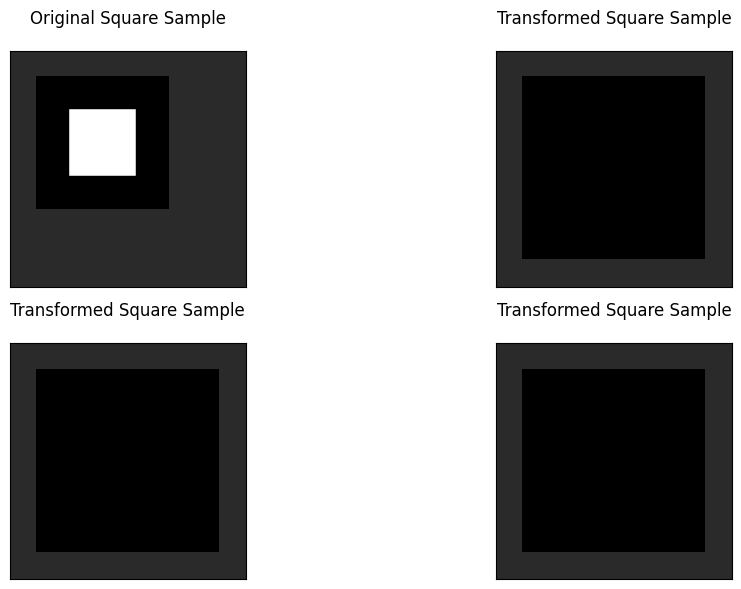

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))

# Show original square
axes[0, 0].imshow(white_box_w_black_bcg)
axes[0, 0].set_title("Original Square Sample", pad=20, fontsize=12)
axes[0, 0].set_facecolor('#2a2a2a')  # Dark gray backdrop
axes[0, 0].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

# Show transformed square
axes[0, 1].imshow(transformed_square_1)
axes[0, 1].set_title("Transformed Square Sample", pad=20, fontsize=12)
axes[0, 1].set_facecolor('#2a2a2a')  # Dark gray backdrop
axes[0, 1].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

# Show transformed square
axes[1, 0].imshow(transformed_square_1)
axes[1, 0].set_title("Transformed Square Sample", pad=20, fontsize=12)
axes[1, 0].set_facecolor('#2a2a2a')  # Dark gray backdrop
axes[1, 0].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

# Show transformed square
axes[1, 1].imshow(transformed_square_1)
axes[1, 1].set_title("Transformed Square Sample", pad=20, fontsize=12)
axes[1, 1].set_facecolor('#2a2a2a')  # Dark gray backdrop
axes[1, 1].tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)


# Add padding by adjusting limits
padding = 20
for ax1 in axes:
    for ax in ax1: 
        ax.set_xlim(-padding, transformed_square_1.shape[1] + padding)
        ax.set_ylim(transformed_square_1.shape[0] + padding, -padding)


plt.tight_layout()
plt.show()

## Trying simple wallpaper application

In [25]:
vector = [116, 257, 129]
vector = np.array(vector) - 128
normal_unit = vector / np.linalg.norm(vector)
print(normal_unit)

[-0.09262061  0.99567156  0.00771838]


In [26]:
def align_to_normal(normal):
    """Create rotation matrix to align Z-axis to given normal"""
    normal = np.array(normal, dtype=float)
    normal = normal / np.linalg.norm(normal)  # Normalize
    
    default = np.array([0, 0, 1])
    
    # If already aligned
    if np.allclose(normal, default):
        return np.eye(3)
    
    # If opposite direction
    if np.allclose(normal, -default):
        return np.diag([1, -1, -1])
    
    # Rodrigues' rotation formula
    v = np.cross(default, normal)
    c = np.dot(default, normal)
    s = np.linalg.norm(v)
    
    # Skew-symmetric cross-product matrix
    vx = np.array([[0, -v[2], v[1]],
                   [v[2], 0, -v[0]],
                   [-v[1], v[0], 0]])
    
    R = np.eye(3) + vx + vx @ vx * ((1 - c) / (s * s))
    return R

In [27]:
R_z = align_to_normal(normal_unit)
print("Rotation Matrix:\n", R_z)

Rotation Matrix:
 [[ 0.99148713  0.09151337 -0.09262061]
 [ 0.09151337  0.01623126  0.99567156]
 [ 0.09262061 -0.99567156  0.00771838]]


In [28]:
vector = [116, 257, 129]
vector = np.array(vector) - 128
normal_unit = vector / np.linalg.norm(vector)
print(normal_unit)

[-0.09262061  0.99567156  0.00771838]


# Normal Wallpaper Visualisation

In [36]:
# Helper function to draw arrow representing normal vector
def draw_normal_arrow(img, centroid, normal_vector, arrow_length=80, arrow_color=(255, 255, 0), thickness=3):
    """
    Draw an arrow representing the normal vector on the image.
    
    Parameters:
    -----------
    img : np.ndarray
        Image to draw on (will be copied, not modified in place)
    centroid : tuple
        (x, y) coordinates of the arrow tail
    normal_vector : np.ndarray
        RGB normal vector [R, G, B] in range [0, 255]
    arrow_length : int
        Fixed length of the arrow in pixels (default: 80)
    arrow_color : tuple
        RGB color for the arrow (default: yellow)
    thickness : int
        Thickness of the arrow line (default: 3)
    
    Returns:
    --------
    np.ndarray : Image with arrow drawn
    """
    img_with_arrow = img.copy()
    
    # Convert normal from RGB space to direction vector
    normal = normal_vector - 128
    normal_unit = normal / np.linalg.norm(normal)
    
    # Project 3D normal to 2D image plane (use x and y components)
    # Scale by arrow_length
    dx = normal_unit[0] * arrow_length
    dy = normal_unit[1] * arrow_length
    
    # Calculate arrow end point
    start_point = (int(centroid[0]), int(centroid[1]))
    end_point = (int(centroid[0] + dx), int(centroid[1] + dy))
    
    # Draw arrow
    cv2.arrowedLine(img_with_arrow, start_point, end_point, 
                    arrow_color, thickness, tipLength=0.3)
    
    return img_with_arrow


def draw_3d_plane_projection(img, centroid, normal_vector, plane_size=20, plane_color=(0, 255, 255), alpha=0.7):
    """
    Draw a 3D plane projection showing wall orientation based on normal vector.
    
    Parameters:
    -----------
    img : np.ndarray
        Image to draw on (will be copied, not modified in place)
    centroid : tuple
        (x, y) coordinates where plane should be centered
    normal_vector : np.ndarray
        RGB normal vector [R, G, B] in range [0, 255]
    plane_size : int
        Size of the plane square in pixels (default: 20)
    plane_color : tuple
        RGB color for the plane (default: cyan)
    alpha : float
        Transparency of the plane (default: 0.7)
    
    Returns:
    --------
    np.ndarray : Image with 3D plane drawn
    """
    img_with_plane = img.copy()
    
    # Convert normal from RGB space to direction vector
    normal = normal_vector - 128
    normal_unit = normal / np.linalg.norm(normal)
    
    # Create rotation matrix to align Z-axis with normal
    R = align_to_normal(normal_unit)
    
    # Define 3D corners of square plane centered at origin
    half = plane_size / 2
    corners_3d = np.array([
        [-half, -half, 0],
        [half, -half, 0],
        [half, half, 0],
        [-half, half, 0]
    ], dtype=np.float32)
    
    # Apply rotation
    rotated_corners = (R @ corners_3d.T).T
    
    # Simple perspective projection parameters
    focal_length = 500  # Adjust for perspective strength
    distance = 50  # Distance from camera
    
    # Move plane away from camera
    rotated_corners[:, 2] += distance
    
    # Project to 2D
    projected = np.zeros((4, 2), dtype=np.float32)
    for i in range(4):
        x, y, z = rotated_corners[i]
        if z != 0:  # Avoid division by zero
            projected[i, 0] = (x * focal_length / z) + centroid[0]
            projected[i, 1] = (y * focal_length / z) + centroid[1]
        else:
            projected[i, 0] = centroid[0]
            projected[i, 1] = centroid[1]
    
    # Convert to integer coordinates
    pts = projected.astype(np.int32)
    
    # Create overlay with plane
    overlay = img_with_plane.copy()
    cv2.fillPoly(overlay, [pts], plane_color)
    
    # Add border to plane
    cv2.polylines(overlay, [pts], isClosed=True, color=(255, 255, 255), thickness=2)
    
    # Blend with original image
    img_with_plane = cv2.addWeighted(img_with_plane, 1 - alpha, overlay, alpha, 0)
    
    return img_with_plane


def draw_3d_plane_with_texture(img, centroid, normal_vector, texture_img, plane_size=20, alpha=0.7):
    """
    Draw a 3D plane projection with a texture image mapped onto it.
    
    Parameters:
    -----------
    img : np.ndarray
        Image to draw on (will be copied, not modified in place)
    centroid : tuple
        (x, y) coordinates where plane should be centered
    normal_vector : np.ndarray
        RGB normal vector [R, G, B] in range [0, 255]
    texture_img : np.ndarray
        Texture image to map onto the plane (will be resized to plane_size x plane_size)
    plane_size : int
        Size of the plane square in pixels (default: 20)
    alpha : float
        Transparency of the plane (default: 0.7)
    
    Returns:
    --------
    np.ndarray : Image with textured 3D plane drawn
    """
    img_with_plane = img.copy()
    
    # Resize texture to plane_size x plane_size
    texture_resized = cv2.resize(texture_img, (plane_size, plane_size))
    
    # Convert normal from RGB space to direction vector
    normal = normal_vector - 128
    normal[0] = -normal[0]  # Invert X to match image coordinate system
    normal_unit = normal / np.linalg.norm(normal)
    
    # Create rotation matrix to align Z-axis with normal
    R = align_to_normal(normal_unit)
    
    # Define 3D corners of square plane centered at origin
    half = plane_size / 2
    corners_3d = np.array([
        [-half, -half, 0],
        [half, -half, 0],
        [half, half, 0],
        [-half, half, 0]
    ], dtype=np.float32)
    
    # Apply rotation
    rotated_corners = (R @ corners_3d.T).T
    
    # Simple perspective projection parameters
    focal_length = 500  # Adjust for perspective strength
    distance = 50  # Distance from camera
    
    # Move plane away from camera
    rotated_corners[:, 2] += distance
    
    # Project to 2D
    projected = np.zeros((4, 2), dtype=np.float32)
    for i in range(4):
        x, y, z = rotated_corners[i]
        if z != 0:  # Avoid division by zero
            projected[i, 0] = (x * focal_length / z) + centroid[0]
            projected[i, 1] = (y * focal_length / z) + centroid[1]
        else:
            projected[i, 0] = centroid[0]
            projected[i, 1] = centroid[1]
    
    # Convert to float32 for perspective transform
    pts_dst = projected.astype(np.float32)
    
    # Source points (corners of the texture image)
    pts_src = np.float32([
        [0, 0],
        [plane_size, 0],
        [plane_size, plane_size],
        [0, plane_size]
    ])
    
    # Calculate perspective transform matrix
    M = cv2.getPerspectiveTransform(pts_src, pts_dst)
    
    # Warp the texture image to match the perspective
    h, w = img.shape[:2]
    warped_texture = cv2.warpPerspective(texture_resized, M, (w, h))
    
    # Create mask for the warped region
    mask = np.zeros((h, w), dtype=np.uint8)
    pts_int = pts_dst.astype(np.int32)
    cv2.fillPoly(mask, [pts_int], 255)
    
    # Convert mask to 3 channels
    mask_3ch = cv2.cvtColor(mask, cv2.COLOR_GRAY2RGB) / 255.0
    
    # Blend the warped texture with the original image
    overlay = img_with_plane.copy().astype(np.float32)
    warped_texture = warped_texture.astype(np.float32)
    
    # Apply alpha blending only where the mask is non-zero
    overlay = overlay * (1 - mask_3ch * alpha) + warped_texture * mask_3ch * alpha
    
    # Add border to plane
    cv2.polylines(overlay.astype(np.uint8), [pts_int], isClosed=True, 
                  color=(255, 255, 255), thickness=2)
    
    return overlay.astype(np.uint8)

## Full Wall Texture Overlay with Perspective

The `overlay_tiled_texture_on_wall()` function applies a tiled texture across an entire wall component with proper perspective transformation and strict pixel masking.

**Key Features:**
- **Tiled Pattern**: Repeats texture seamlessly across the wall
- **Perspective Correct**: Applies 3D transformation based on wall's normal vector
- **Precise Masking**: Constrains texture to exact wall pixels (no bleeding)
- **Adjustable**: Control tile size, transparency, and projection parameters

In [ ]:
# Visualization: Show each wall with normal vector arrow and 3D plane
colors = [[255, 0, 0], [0, 255, 0], [0, 0, 255], [255, 255, 0], [255, 0, 255]]

for i, wall in enumerate(wall_components[:5]):
    # Create base overlay with colored wall component
    wall_overlay = overlay_wall_component_on_image(
        img, 
        wall, 
        overlay_color=colors[i % len(colors)],
        alpha=0.5
    )
    
    # Get wall properties
    normal_vector_rgb = wall['normal_vector']
    centroid = (wall['centroid_x'], wall['centroid_y'])
    
    # Draw normal vector arrow (yellow)
    wall_overlay = draw_normal_arrow(
        wall_overlay, 
        centroid, 
        normal_vector_rgb,
        arrow_length=80,
        arrow_color=(255, 255, 0),
        thickness=3
    )
    
    # Draw 3D plane projection (cyan)
    wall_overlay = draw_3d_plane_projection(
        wall_overlay,
        centroid,
        normal_vector_rgb,
        plane_size=50,
        plane_color=(0, 255, 255),
        alpha=0.7
    )
    
    # Calculate and print normal info
    normal_vector = normal_vector_rgb - 128 
    normal_unit = normal_vector / np.linalg.norm(normal_vector)
    
    print(f"Wall {wall['wall_id']}:")
    print(f"  Normal RGB: {normal_vector_rgb}")
    print(f"  Normal Unit: {normal_unit}")
    print(f"  Centroid: {centroid}")
    
    # Display
    plt.figure(figsize=(10, 8))
    plt.imshow(wall_overlay)
    plt.title(f"Wall {wall['wall_id']} (Cluster {wall['cluster_id']}, Confidence: {wall['avg_wall_confidence']:.3f})\nYellow Arrow = Normal Vector | Cyan Square = 3D Plane")
    plt.axis('off')
    plt.show()

In [31]:
def trial_func(img):
    arrow_length = 80
    arrow_color = (255, 255, 0)
    thickness = 3
    centroid = (250, 250)
    normal_vector = np.array([116, 257, 129])  # Example normal
    img_with_arrow = img.copy()
    
    # Convert normal from RGB space to direction vector
    normal = normal_vector - 128
    normal_unit = normal / np.linalg.norm(normal)
    
    # Project 3D normal to 2D image plane (use x and y components)
    # Scale by arrow_length
    dx = normal_unit[0] * arrow_length
    dy = normal_unit[1] * arrow_length
    
    # Calculate arrow end point
    start_point = (int(centroid[0]), int(centroid[1]))
    end_point = (int(centroid[0]+100), int(centroid[1]-100))
    
    # Draw arrow
    cv2.arrowedLine(img_with_arrow, start_point, end_point, 
                    arrow_color, thickness, tipLength=0.3)
    
    return img_with_arrow

In [ ]:
plt.imshow(trial_func(img))

## Example: Using Texture Projection

Now we can use `draw_3d_plane_with_texture` to project an actual image onto the plane instead of a solid color.

In [ ]:
# Example: Create a sample texture (you can replace this with any image)
# Let's create a simple checkerboard pattern as an example texture
texture_size = 100
checkerboard = np.zeros((texture_size, texture_size, 3), dtype=np.uint8)

# Create checkerboard pattern
square_size = 10
for i in range(0, texture_size, square_size):
    for j in range(0, texture_size, square_size):
        if (i // square_size + j // square_size) % 2 == 0:
            checkerboard[i:i+square_size, j:j+square_size] = [255, 200, 100]  # Orange
        else:
            checkerboard[i:i+square_size, j:j+square_size] = [100, 150, 255]  # Light blue

# Show the texture
plt.figure(figsize=(4, 4))
plt.imshow(checkerboard)
plt.title("Sample Texture (Checkerboard)")
plt.axis('off')
plt.show()

In [ ]:
# Apply textured projection to the first wall
colors = [[255, 0, 0], [0, 255, 0], [0, 0, 255], [255, 255, 0], [255, 0, 255]]

for i, wall in enumerate(wall_components):  # Show first 3 walls
    # Create base overlay with colored wall component
    wall_overlay = overlay_wall_component_on_image(
        img, 
        wall, 
        overlay_color=colors[i % len(colors)],
        alpha=0.3
    )
    
    # Get wall properties
    normal_vector_rgb = wall['normal_vector']
    centroid = (int(wall['centroid_x']), int(wall['centroid_y']))
    
    # Draw textured 3D plane projection
    wall_overlay = draw_3d_plane_with_texture(
        wall_overlay,
        centroid,
        normal_vector_rgb,
        texture_img=checkerboard,
        plane_size=80,
        alpha=0.8
    )
    
    # Calculate and print normal info
    normal_vector = normal_vector_rgb - 128 
    normal_unit = normal_vector / np.linalg.norm(normal_vector)
    
    print(f"Wall {wall['wall_id']}:")
    print(f"  Normal RGB: {normal_vector_rgb}")
    print(f"  Normal Unit: {normal_unit}")
    print(f"  Centroid: {centroid}")
    
    # Display
    plt.figure(figsize=(12, 10))
    plt.imshow(wall_overlay)
    plt.title(f"Wall {wall['wall_id']} with Textured Projection\\n(Cluster {wall['cluster_id']}, Confidence: {wall['avg_wall_confidence']:.3f})")
    plt.axis('off')
    plt.show()

In [47]:
def overlay_tiled_texture_on_wall(
    original_img,
    wall_component,
    texture_img,
    tile_size_pixels=100,
    alpha=0.7,
    focal_length=500,
    camera_distance=50
):
    """
    Overlay a tiled texture onto an entire wall component with perspective transformation.
    
    This function tiles a texture pattern across the full wall area, applies perspective
    transformation based on the wall's normal vector, and strictly masks to wall pixels.
    
    Strategy: "Tile-Before-Warp"
    1. Create oversized tiled canvas (larger than wall bounding box)
    2. Define 3D plane corners matching wall dimensions
    3. Apply perspective transformation using wall's normal vector
    4. Warp entire tiled canvas with cv2.warpPerspective()
    5. Mask to exact wall pixels using pixel_mask
    6. Alpha blend with original image
    
    Parameters:
    -----------
    original_img : np.ndarray
        Original image (H, W, 3)
    wall_component : dict
        Wall component dictionary containing:
        - 'pixel_mask': Binary mask of exact wall pixels
        - 'normal_vector': RGB normal vector [R, G, B]
        - 'x', 'y', 'width', 'height': Bounding box
        - 'centroid_x', 'centroid_y': Center coordinates
    texture_img : np.ndarray
        Texture image to tile across the wall
    tile_size_pixels : int
        Size of each texture tile in pixels (default: 100)
    alpha : float
        Transparency (0.0=transparent, 1.0=opaque, default: 0.7)
    focal_length : int
        Camera focal length for perspective projection (default: 500)
    camera_distance : int
        Distance of plane from camera (default: 50)
    
    Returns:
    --------
    np.ndarray : Image with tiled texture overlay on wall
    """
    
    # STEP 1: Extract wall component data
    pixel_mask = wall_component['pixel_mask']
    normal_vector = wall_component['normal_vector'].copy()
    bbox_x, bbox_y = wall_component['x'], wall_component['y']
    bbox_w, bbox_h = wall_component['width'], wall_component['height']
    centroid = (wall_component['centroid_x'], wall_component['centroid_y'])
    
    # STEP 2: Create oversized tiled texture canvas
    # Scale factor provides safety margin to prevent edge clipping during perspective warp
    scale_factor = 1.5
    canvas_w = int(bbox_w * scale_factor)
    canvas_h = int(bbox_h * scale_factor)
    
    # Calculate number of tiles needed to cover canvas
    tiles_x = int(np.ceil(canvas_w / tile_size_pixels)) + 2  # +2 for safety
    tiles_y = int(np.ceil(canvas_h / tile_size_pixels)) + 2
    
    # Resize texture to tile size and create tiled canvas
    texture_tile = cv2.resize(texture_img, (tile_size_pixels, tile_size_pixels))
    tiled_texture = np.tile(texture_tile, (tiles_y, tiles_x, 1))
    
    # Crop to desired canvas size (centered)
    tiled_h, tiled_w = tiled_texture.shape[:2]
    start_x = (tiled_w - canvas_w) // 2
    start_y = (tiled_h - canvas_h) // 2
    tiled_texture = tiled_texture[start_y:start_y+canvas_h, start_x:start_x+canvas_w]
    
    # STEP 3: Define 3D plane corners for perspective transformation
    # Use bounding box dimensions as the 3D plane size
    half_w = bbox_w / 2
    half_h = bbox_h / 2
    
    corners_3d = np.array([
        [-half_w, -half_h, 0],  # Top-left
        [half_w, -half_h, 0],   # Top-right
        [half_w, half_h, 0],    # Bottom-right
        [-half_w, half_h, 0]    # Bottom-left
    ], dtype=np.float32)
    
    # STEP 4: Apply rotation based on normal vector
    # Convert RGB normal to direction vector
    normal = normal_vector - 128
    normal_unit = normal / np.linalg.norm(normal)
    
    # Get rotation matrix using existing align_to_normal function
    R = align_to_normal(normal_unit)
    rotated_corners = (R @ corners_3d.T).T
    
    # STEP 5: Project to 2D using perspective projection
    rotated_corners[:, 2] += camera_distance
    
    projected = np.zeros((4, 2), dtype=np.float32)
    for i in range(4):
        x, y, z = rotated_corners[i]
        if z != 0:  # Avoid division by zero
            projected[i, 0] = (x * focal_length / z) + centroid[0]
            projected[i, 1] = (y * focal_length / z) + centroid[1]
        else:
            projected[i, 0] = centroid[0]
            projected[i, 1] = centroid[1]
    
    # STEP 6: Calculate perspective transform matrix
    # Source: corners of tiled texture canvas
    pts_src = np.float32([
        [0, 0],
        [canvas_w, 0],
        [canvas_w, canvas_h],
        [0, canvas_h]
    ])
    
    pts_dst = projected.astype(np.float32)
    M = cv2.getPerspectiveTransform(pts_src, pts_dst)
    
    # STEP 7: Warp tiled texture to perspective
    img_h, img_w = original_img.shape[:2]
    warped_texture = cv2.warpPerspective(
        tiled_texture, 
        M, 
        (img_w, img_h),
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0)
    )
    
    # # STEP 8: Create composite mask (warp region AND pixel_mask)
    # # First create bounding box mask from projected corners
    # warp_mask = np.zeros((img_h, img_w), dtype=np.uint8)
    # pts_int = pts_dst.astype(np.int32)
    # cv2.fillPoly(warp_mask, [pts_int], 255)
    
    # # Combine with pixel_mask using AND operation
    # # This ensures texture only appears within actual wall pixels
    # final_mask = np.logical_and(warp_mask > 0, pixel_mask)
    
    # # Convert to 3-channel for blending
    # final_mask_3ch = np.stack([final_mask] * 3, axis=-1).astype(np.float32)
    
    # # STEP 9: Alpha blend with original image
    # result = original_img.copy().astype(np.float32)
    # warped_texture = warped_texture.astype(np.float32)
    
    # # Apply blending only where final_mask is True
    # result = result * (1 - final_mask_3ch * alpha) + warped_texture * final_mask_3ch * alpha
    
    # STEP 8: Create composite mask (warp region AND pixel_mask)
    # First create bounding box mask from projected corners
    warp_mask = np.zeros((img_h, img_w), dtype=np.uint8)
    pts_int = pts_dst.astype(np.int32)
    cv2.fillPoly(warp_mask, [pts_int], 255)
    
    # Combine with pixel_mask using AND operation
    # This ensures texture only appears within actual wall pixels
    final_mask = np.logical_and(warp_mask, pixel_mask)
    
    # Convert to 3-channel for blending
    final_mask_3ch = np.stack([final_mask] * 3, axis=-1).astype(np.float32)
    
    # STEP 9: Alpha blend with original image
    result = original_img.copy().astype(np.float32)
    warped_texture = warped_texture.astype(np.float32)
    
    # Apply blending only where final_mask is True
    result = result * (1 - final_mask_3ch * alpha) + warped_texture * final_mask_3ch * alpha
    

    return result.astype(np.uint8)

In [ ]:
# Demo: Apply tiled texture to wall components
# Using the existing checkerboard texture created earlier

for i, wall in enumerate(wall_components[:4]):  # Apply to first 3 walls
    # Apply tiled texture overlay
    result = overlay_tiled_texture_on_wall(
        original_img=img,
        wall_component=wall,
        texture_img=checkerboard,
        tile_size_pixels=80,
        alpha=0.8,
        focal_length=500,
        camera_distance=50
    )
    
    # Display result
    plt.figure(figsize=(14, 10))
    plt.imshow(result)
    plt.title(f"Wall {wall['wall_id']} with Tiled Texture Overlay\\n" +
              f"(Cluster {wall['cluster_id']}, Area: {wall['area']} px, " +
              f"Confidence: {wall['avg_wall_confidence']:.3f})",
              fontsize=14, pad=15)
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    print(f"Wall {wall['wall_id']}: Texture tiled across {wall['width']}x{wall['height']} px area")

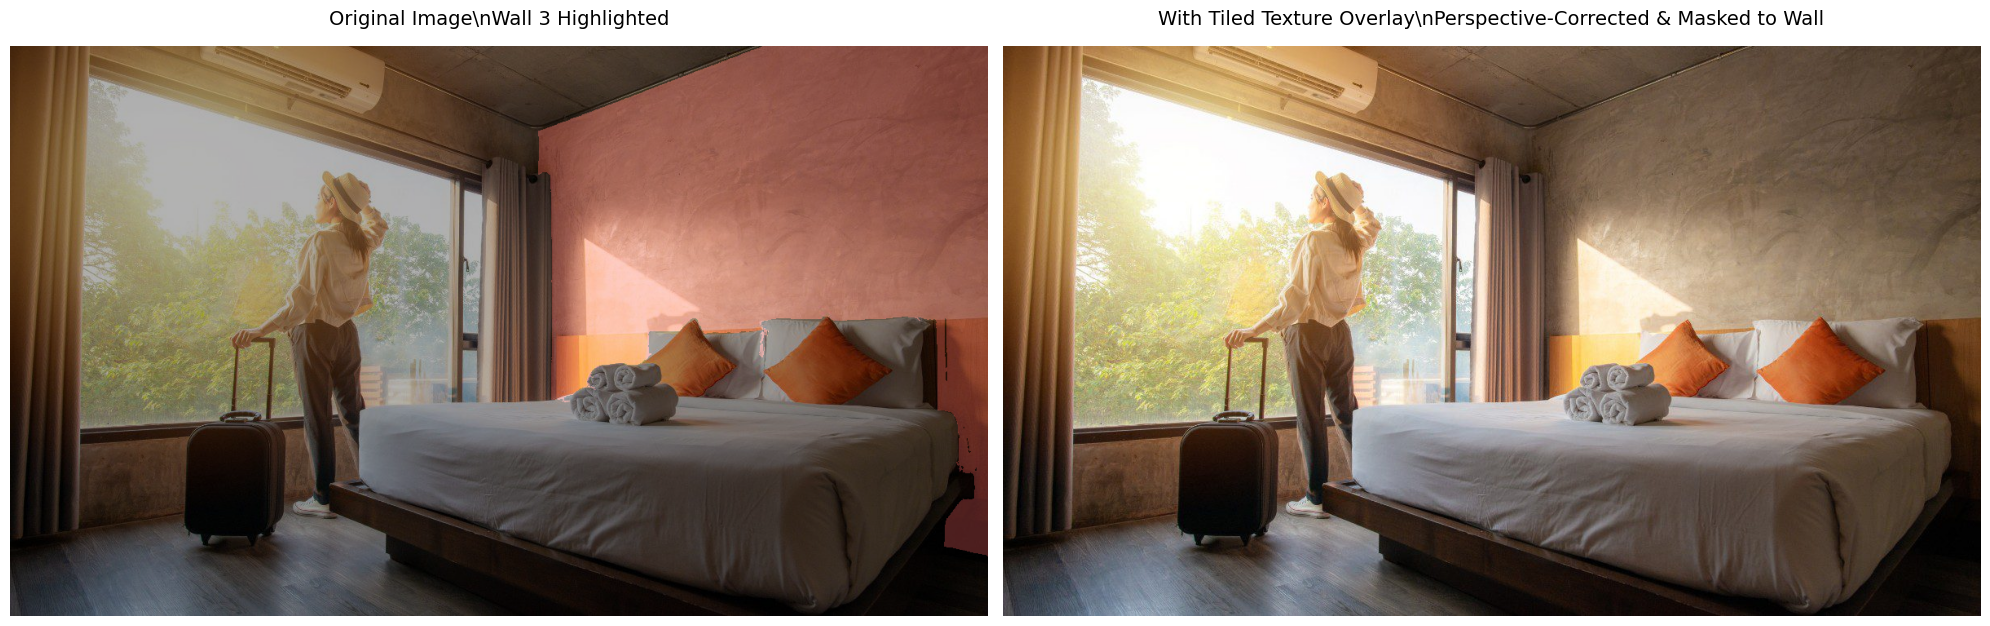

Wall dimensions: 552x627 pixels
Wall area: 191322 pixels
Texture successfully tiled and perspective-transformed to match wall orientation!


In [49]:
# Side-by-side comparison: Original vs Textured
wall_to_showcase = wall_components[3]  # The large wall

# Original with wall highlighted
original_highlighted = overlay_wall_component_on_image(
    img,
    wall_to_showcase,
    overlay_color=[255, 100, 100],
    alpha=0.3
)

# Textured version
textured_result = overlay_tiled_texture_on_wall(
    original_img=img,
    wall_component=wall_to_showcase,
    texture_img=checkerboard,
    tile_size_pixels=60,
    alpha=0.85
)

# Display side by side
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

axes[0].imshow(original_highlighted)
axes[0].set_title(f"Original Image\\nWall {wall_to_showcase['wall_id']} Highlighted", 
                  fontsize=14, pad=15)
axes[0].axis('off')

axes[1].imshow(textured_result)
axes[1].set_title(f"With Tiled Texture Overlay\\nPerspective-Corrected & Masked to Wall", 
                  fontsize=14, pad=15)
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"Wall dimensions: {wall_to_showcase['width']}x{wall_to_showcase['height']} pixels")
print(f"Wall area: {wall_to_showcase['area']} pixels")
print(f"Texture successfully tiled and perspective-transformed to match wall orientation!")